In [1]:
!pip -q install pycocotools opencv-python-headless seaborn

import os
import json
import zipfile
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pycocotools.coco import COCO
from matplotlib.patches import Rectangle

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
!pip install -q huggingface_hub

import os
import json
import random
from huggingface_hub import hf_hub_download

# Dataset information
REPO_ID = "iisc-aim/BMD-45"
DATASET_ROOT = "/content/BMD45"

# Download the COCO annotation JSON
ANNOTATION_FILE = hf_hub_download(
    repo_id=REPO_ID,
    filename="BMD-45-Train/_annotations.coco.json",
    repo_type="dataset",
    local_dir=DATASET_ROOT
)

# Load image information
with open(ANNOTATION_FILE, "r") as f:
    dataset_info = json.load(f)

# Image folder
IMAGE_DIR = os.path.join(DATASET_ROOT, "BMD-45-Train")

# Download only 12 sample images for visualization
sample_images = random.sample(
    dataset_info["images"],
    min(12, len(dataset_info["images"]))
)

for img in sample_images:

    filename = img["file_name"]

    hf_hub_download(
        repo_id=REPO_ID,
        filename=f"BMD-45-Train/{filename}",
        repo_type="dataset",
        local_dir=DATASET_ROOT
    )

print("Dataset annotations downloaded!")
print("Sample traffic images downloaded!")
print("Annotation file:", ANNOTATION_FILE)
print("Image directory:", IMAGE_DIR)

BMD-45-Train/_annotations.coco.json: reconstructing file:   0%|          |  0.00B / 49.4MB            

BMD-45-Train/_annotations.coco.json: downloading bytes:           |  0.00B            

BMD-45-Train/images_002/380829.png: reconstructing file:   0%|          |  0.00B / 3.36MB            

BMD-45-Train/images_002/380829.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_005/715514.png: reconstructing file:   0%|          |  0.00B / 2.24MB            

BMD-45-Train/images_005/715514.png: downloading bytes:           |  0.00B            

... (17 outputs left out)

BMD-45-Train/images_006/975540.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_002/406856.png: reconstructing file:   0%|          |  0.00B / 3.16MB            

BMD-45-Train/images_002/406856.png: downloading bytes:           |  0.00B            

Dataset annotations downloaded!
Sample traffic images downloaded!
Annotation file: /content/BMD45/BMD-45-Train/_annotations.coco.json
Image directory: /content/BMD45/BMD-45-Train


In [5]:
# OPTION B: Uncomment this cell only if using Google Drive.
# from google.colab import drive
# drive.mount('/content/drive')
#
# DATASET_ROOT = "/content/drive/MyDrive/Indian_Traffic_Dataset"
# print("Dataset folder exists:", os.path.isdir(DATASET_ROOT))

In [6]:
# Find JSON files
json_files = list(Path(DATASET_ROOT).rglob("*.json"))
print("JSON files found:")
for p in json_files[:50]:
    print(" -", p)

if not json_files:
    raise FileNotFoundError("No JSON files found. Check DATASET_ROOT and dataset format.")

# Select a JSON file that looks like COCO (contains images, annotations, categories)
coco_candidates = []
for p in json_files:
    try:
        with open(p, "r", encoding="utf-8") as f:
            obj = json.load(f)
        if all(k in obj for k in ("images", "annotations", "categories")):
            coco_candidates.append(p)
    except Exception:
        pass

if not coco_candidates:
    raise ValueError(
        "No COCO-style JSON found. Expected keys: images, annotations, categories. "
        "This dataset may need conversion to COCO format."
    )

print("\nCOCO-style annotation candidates:")
for p in coco_candidates:
    print(" -", p)

# Default to the first COCO candidate. Change this if you have multiple splits.
ANNOTATION_FILE = str(coco_candidates[0])

# Image folder: set this manually if images are not directly under the dataset root.
IMAGE_DIR = str(Path(ANNOTATION_FILE).parent)

print("\nSelected annotation file:", ANNOTATION_FILE)
print("Initial image directory:", IMAGE_DIR)

# If your image files are stored in a separate folder, change IMAGE_DIR manually, e.g.:
# IMAGE_DIR = "/content/indian_traffic_dataset/train/images"

JSON files found:
 - /content/BMD45/BMD-45-Train/_annotations.coco.json

COCO-style annotation candidates:
 - /content/BMD45/BMD-45-Train/_annotations.coco.json

Selected annotation file: /content/BMD45/BMD-45-Train/_annotations.coco.json
Initial image directory: /content/BMD45/BMD-45-Train


In [7]:
with open(ANNOTATION_FILE, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

required_keys = {"images", "annotations", "categories"}
missing = required_keys - set(coco_data.keys())
if missing:
    raise ValueError(f"Missing required COCO keys: {missing}")

coco = COCO(ANNOTATION_FILE)

images = coco_data["images"]
annotations = coco_data["annotations"]
categories = coco_data["categories"]

print("COCO annotations loaded successfully.")
print(f"Images: {len(images):,}")
print(f"Annotations: {len(annotations):,}")
print(f"Categories: {len(categories):,}")

print("\nSample image record:")
display(pd.DataFrame(images).head(1))

print("\nSample annotation record:")
display(pd.DataFrame(annotations).head(1))

print("\nCategory list:")
display(pd.DataFrame(categories)[["id", "name"]])


loading annotations into memory...
Done (t=2.53s)
creating index...
index created!
COCO annotations loaded successfully.
Images: 35,792
Annotations: 373,132
Categories: 13

Sample image record:


,file_name,height,id,width
0,images_000/41.png,1080,0,1920



Sample annotation record:


,area,bbox,category_id,id,image_id,iscrowd
0,59772.0,"[1595.74, 447.21, 204, 293.00000000000006]",6,1,0,0



Category list:


,id,name
0,0,Hatchback
1,1,Sedan
2,2,SUV
3,3,MUV
4,4,Bus
5,5,Truck
6,6,Three-wheeler
7,7,Two-wheeler
8,8,LCV
9,9,Mini-bus


In [8]:
def resolve_image_path(file_name):
    candidates = [
        Path(IMAGE_DIR) / file_name,
        Path(DATASET_ROOT) / file_name,
        Path(ANNOTATION_FILE).parent / file_name
    ]
    for candidate in candidates:
        if candidate.is_file():
            return str(candidate)
    return None

image_records = []
missing_images = []

for img in images:
    path = resolve_image_path(img["file_name"])
    if path is None:
        missing_images.append(img["file_name"])
    image_records.append({
        "image_id": img["id"],
        "file_name": img["file_name"],
        "width": img.get("width"),
        "height": img.get("height"),
        "path": path
    })

image_df = pd.DataFrame(image_records)

print(f"Image records in JSON: {len(image_df):,}")
print(f"Image files found: {(image_df['path'].notna()).sum():,}")
print(f"Image files missing: {len(missing_images):,}")

if missing_images:
    print("\nFirst missing filenames:")
    for name in missing_images[:10]:
        print(" -", name)

display(image_df.head())

Image records in JSON: 35,792
Image files found: 12
Image files missing: 35,780

First missing filenames:
 - images_000/41.png
 - images_000/47.png
 - images_000/71.png
 - images_000/94.png
 - images_000/170.png
 - images_000/183.png
 - images_000/187.png
 - images_000/224.png
 - images_000/247.png
 - images_000/320.png


,image_id,file_name,width,height,path
0,0,images_000/41.png,1920,1080,None
1,1,images_000/47.png,1920,1080,None
2,3,images_000/71.png,1920,1080,None
3,4,images_000/94.png,1920,1080,None
4,6,images_000/170.png,1920,1080,None


,category_id,category,object_count
7,7,Two-wheeler,171283
6,6,Three-wheeler,65899
0,0,Hatchback,35101
1,1,Sedan,19970
8,8,LCV,18115
2,2,SUV,15573
4,4,Bus,13899
5,5,Truck,9968
3,3,MUV,9092
11,11,Bicycle,4713


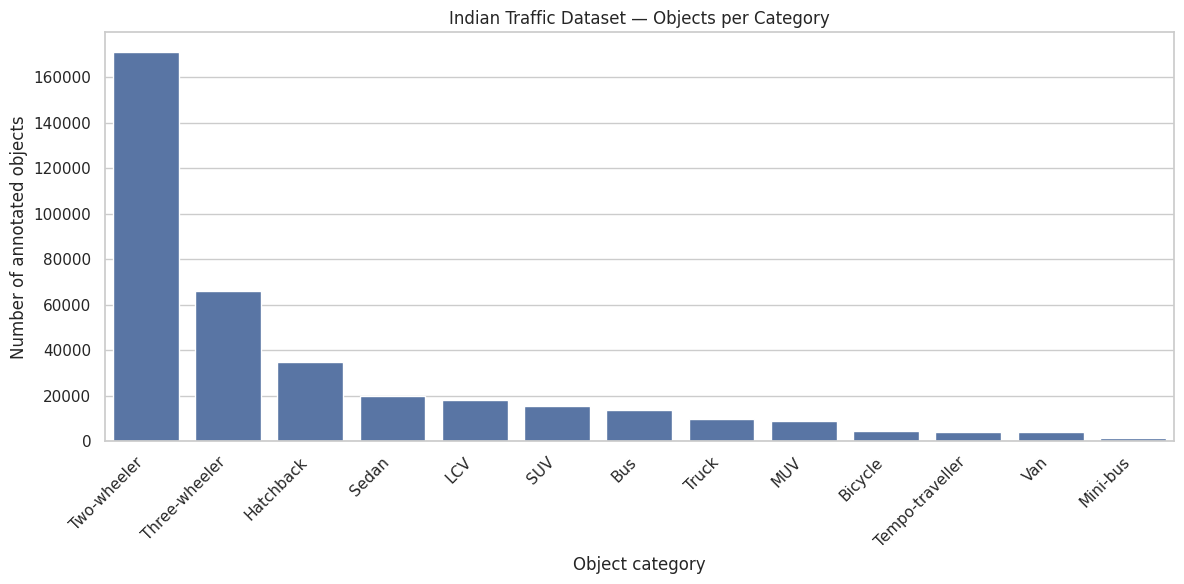

Total labelled objects: 373,132


In [9]:
category_name = {cat["id"]: cat["name"] for cat in categories}
category_id_to_name = category_name

counts = Counter(ann["category_id"] for ann in annotations)

category_df = pd.DataFrame([
    {
        "category_id": cat["id"],
        "category": cat["name"],
        "object_count": counts.get(cat["id"], 0)
    }
    for cat in categories
]).sort_values("object_count", ascending=False)

display(category_df)

plt.figure(figsize=(12, 6))
sns.barplot(data=category_df, x="category", y="object_count")
plt.title("Indian Traffic Dataset — Objects per Category")
plt.xlabel("Object category")
plt.ylabel("Number of annotated objects")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

total_objects = int(category_df["object_count"].sum())
print(f"Total labelled objects: {total_objects:,}")

Image dimension summary:


,width,height
count,35792.0,35792.0
mean,1920.0,1080.0
std,0.0,0.0
min,1920.0,1080.0
25%,1920.0,1080.0
50%,1920.0,1080.0
75%,1920.0,1080.0
max,1920.0,1080.0


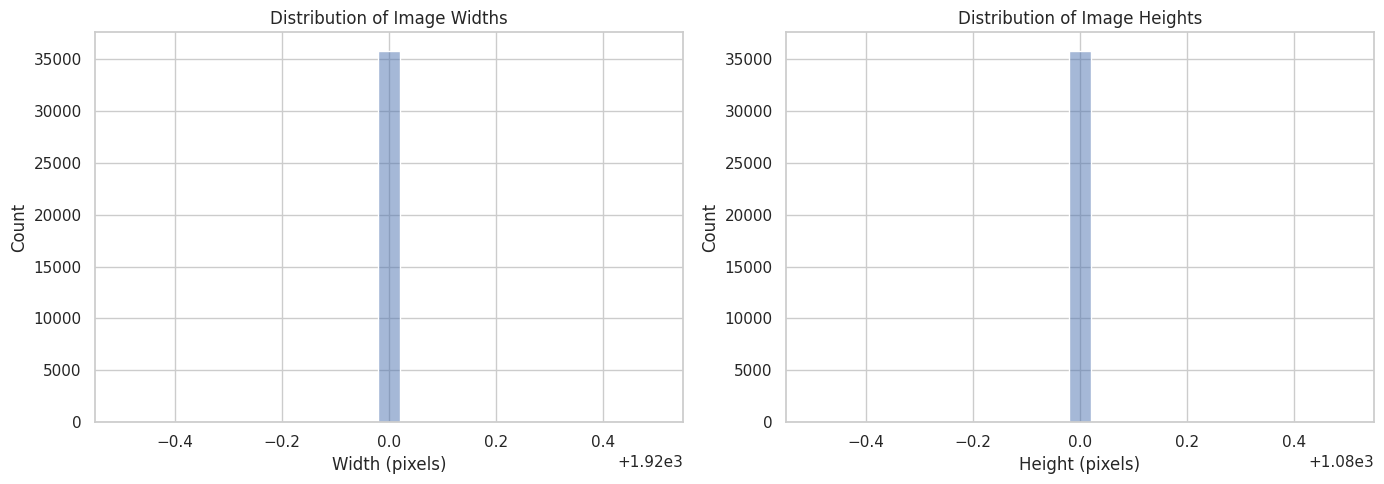

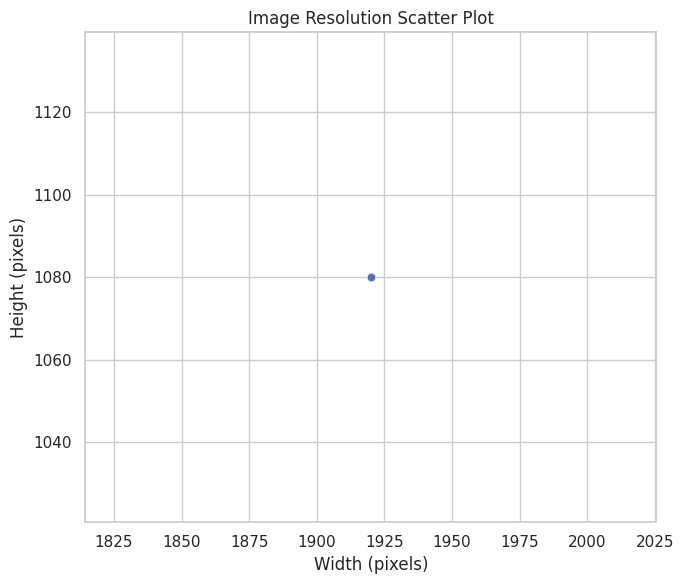

In [10]:
valid_dims = image_df.dropna(subset=["width", "height"]).copy()
valid_dims["width"] = pd.to_numeric(valid_dims["width"], errors="coerce")
valid_dims["height"] = pd.to_numeric(valid_dims["height"], errors="coerce")
valid_dims = valid_dims.dropna(subset=["width", "height"])

print("Image dimension summary:")
display(valid_dims[["width", "height"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(valid_dims["width"], bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Image Widths")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(valid_dims["height"], bins=25, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Image Heights")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
sns.scatterplot(data=valid_dims, x="width", y="height", alpha=0.6)
plt.title("Image Resolution Scatter Plot")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()
plt.show()

In [11]:
image_size_by_id = {
    img["id"]: (img.get("width"), img.get("height"))
    for img in images
}

bbox_rows = []
invalid_bbox_count = 0

for ann in annotations:
    bbox = ann.get("bbox")
    if not bbox or len(bbox) != 4:
        invalid_bbox_count += 1
        continue

    x, y, w, h = map(float, bbox)
    if w <= 0 or h <= 0:
        invalid_bbox_count += 1
        continue

    img_w, img_h = image_size_by_id.get(ann["image_id"], (None, None))
    image_area = (float(img_w) * float(img_h)) if img_w and img_h else np.nan
    box_area = w * h

    bbox_rows.append({
        "image_id": ann["image_id"],
        "category": category_id_to_name.get(ann["category_id"], "unknown"),
        "x": x,
        "y": y,
        "width": w,
        "height": h,
        "area": box_area,
        "normalized_area": box_area / image_area if image_area and image_area > 0 else np.nan
    })

bbox_df = pd.DataFrame(bbox_rows)

print(f"Valid bounding boxes: {len(bbox_df):,}")
print(f"Invalid/malformed boxes skipped: {invalid_bbox_count:,}")
display(bbox_df.head())

print("Bounding-box measurements:")
display(bbox_df[["width", "height", "area", "normalized_area"]].describe())

Valid bounding boxes: 373,132
Invalid/malformed boxes skipped: 0


,image_id,category,x,y,width,height,area,normalized_area
0,0,Three-wheeler,1595.74,447.21,204.0,293.0,59772.0,0.028825
1,0,Two-wheeler,736.03,151.65,122.0,106.0,12932.0,0.006236
2,0,Bicycle,1412.38,854.30,401.0,225.0,90225.0,0.043511
3,0,Bicycle,704.43,169.07,86.0,102.0,8772.0,0.004230
4,1,Sedan,616.87,284.11,382.0,246.0,93972.0,0.045318


Bounding-box measurements:


,width,height,area,normalized_area
count,373132.000000,373132.000000,3.731320e+05,373132.000000
mean,164.394760,170.853470,4.324391e+04,0.020855
std,152.063601,124.853808,9.176656e+04,0.044255
min,3.000000,0.320000,6.000000e+00,0.000003
25%,71.000000,86.000000,6.365000e+03,0.003070
50%,119.000000,135.000000,1.612500e+04,0.007776
75%,202.000000,216.000000,4.188800e+04,0.020201
max,1920.000000,1080.000000,2.071289e+06,0.998886


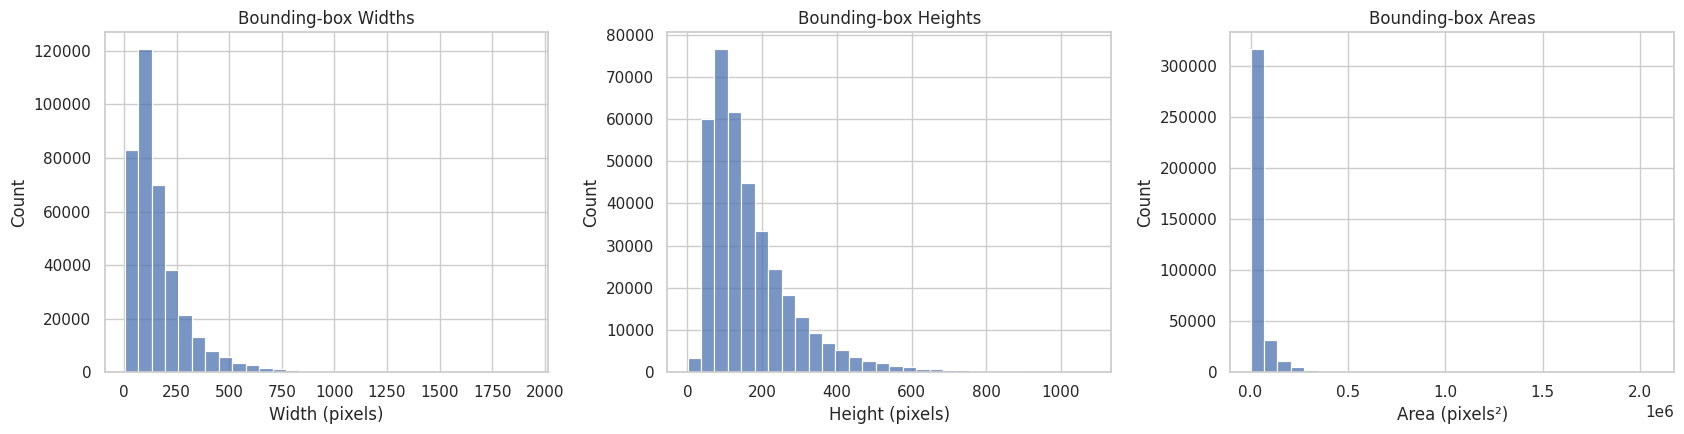

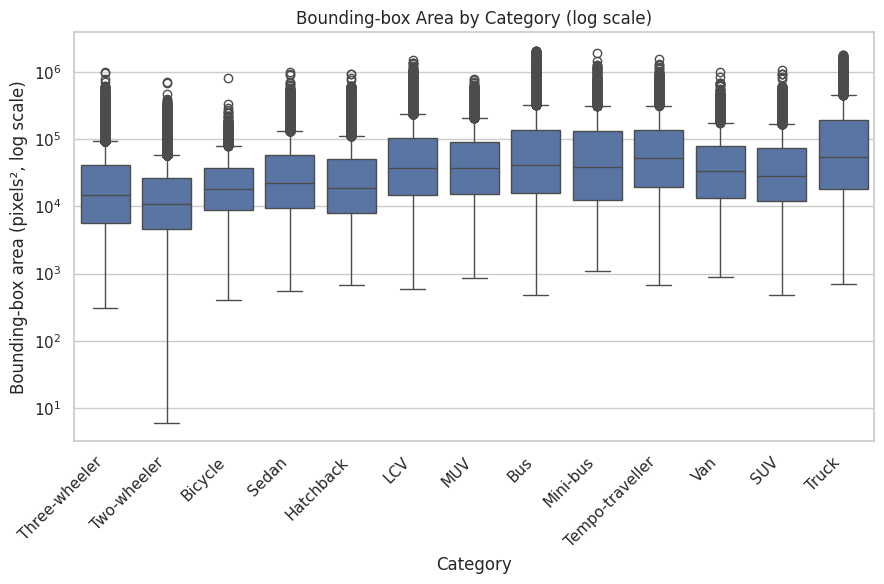

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(bbox_df["width"], bins=30, ax=axes[0])
axes[0].set_title("Bounding-box Widths")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(bbox_df["height"], bins=30, ax=axes[1])
axes[1].set_title("Bounding-box Heights")
axes[1].set_xlabel("Height (pixels)")

sns.histplot(bbox_df["area"], bins=30, ax=axes[2])
axes[2].set_title("Bounding-box Areas")
axes[2].set_xlabel("Area (pixels²)")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.boxplot(data=bbox_df, x="category", y="area")
plt.yscale("log")
plt.title("Bounding-box Area by Category (log scale)")
plt.xlabel("Category")
plt.ylabel("Bounding-box area (pixels², log scale)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Objects-per-image summary:


,objects_per_image
count,35792.000000
mean,10.425011
std,7.022555
min,0.000000
25%,5.000000
50%,9.000000
75%,14.000000
max,65.000000


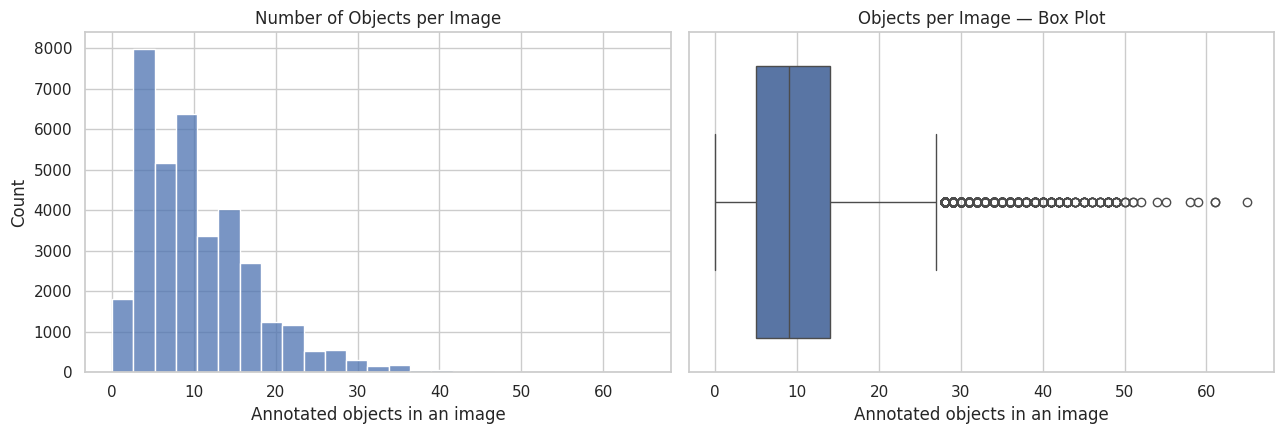

In [13]:
objects_per_image = Counter(ann["image_id"] for ann in annotations)

objects_df = pd.DataFrame({
    "image_id": [img["id"] for img in images]
})
objects_df["object_count"] = objects_df["image_id"].map(objects_per_image).fillna(0).astype(int)

print("Objects-per-image summary:")
display(objects_df["object_count"].describe().to_frame("objects_per_image"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(objects_df["object_count"], bins=25, ax=axes[0])
axes[0].set_title("Number of Objects per Image")
axes[0].set_xlabel("Annotated objects in an image")

sns.boxplot(x=objects_df["object_count"], ax=axes[1])
axes[1].set_title("Objects per Image — Box Plot")
axes[1].set_xlabel("Annotated objects in an image")

plt.tight_layout()
plt.show()


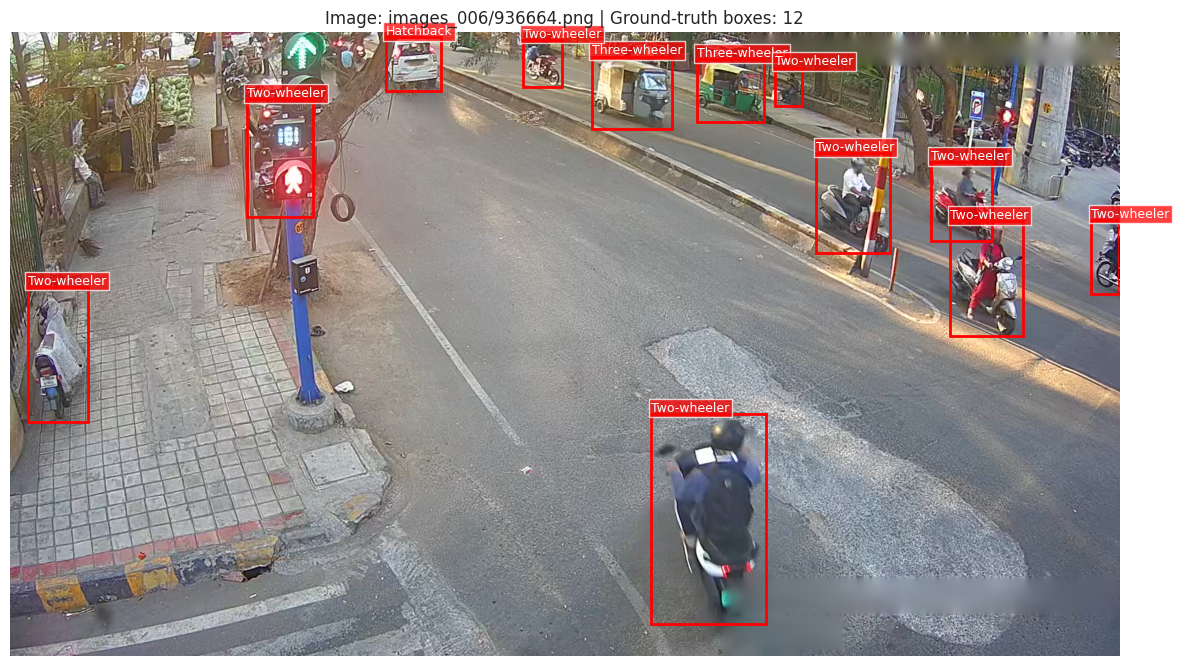

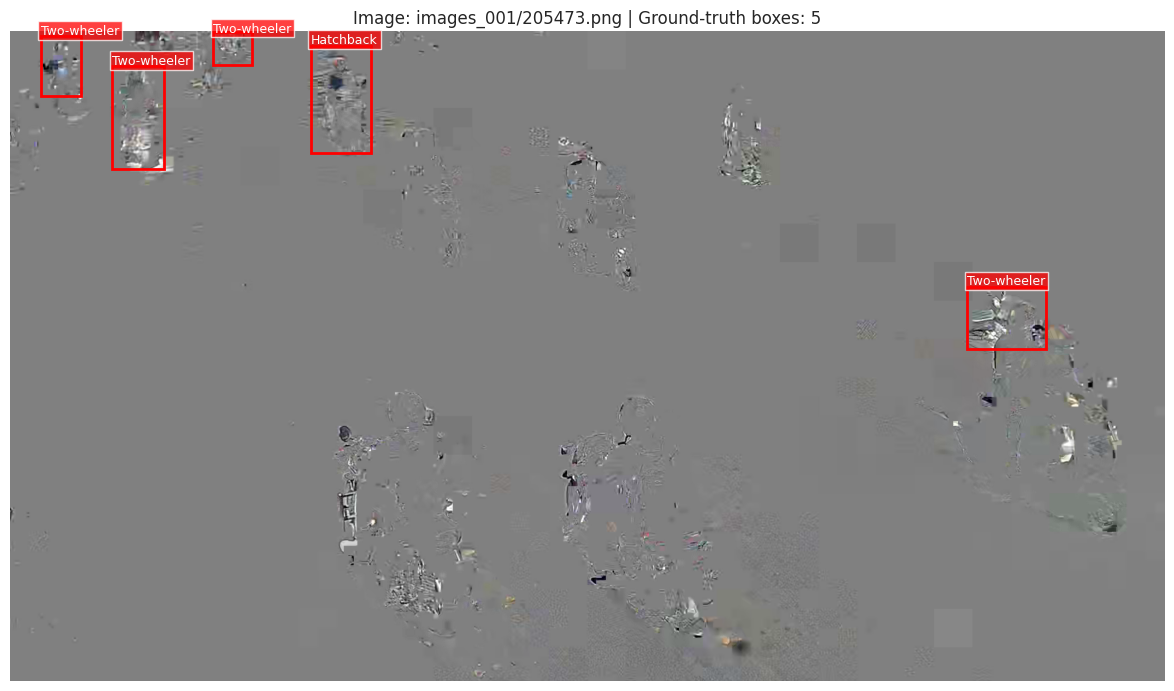

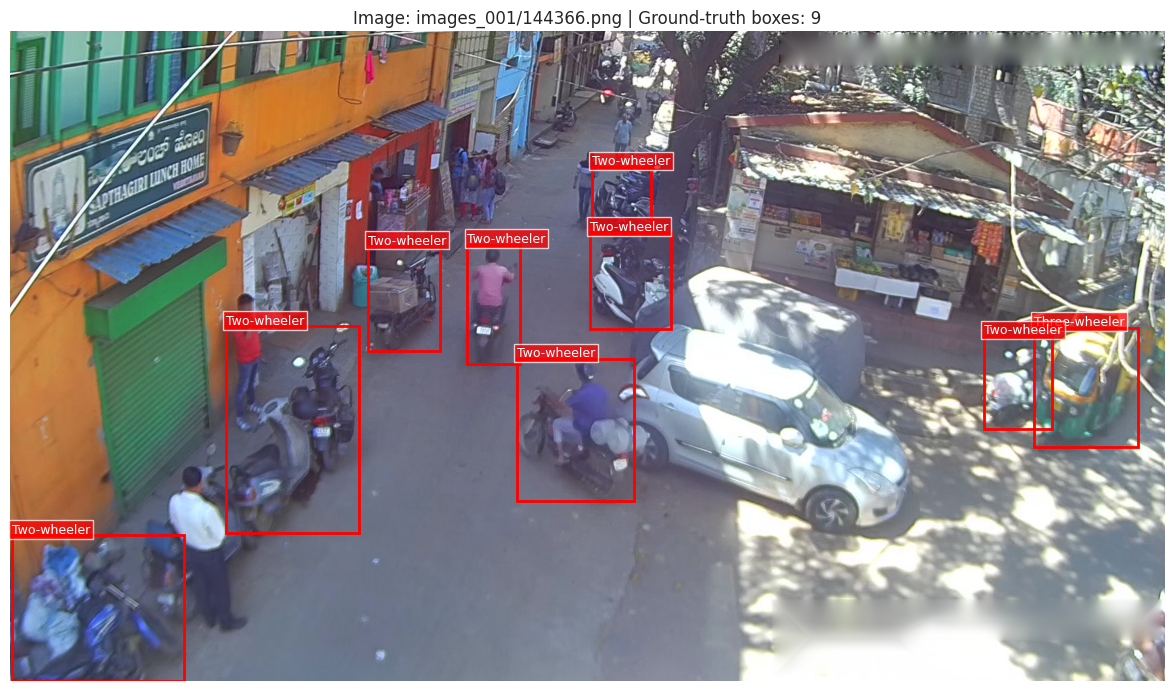

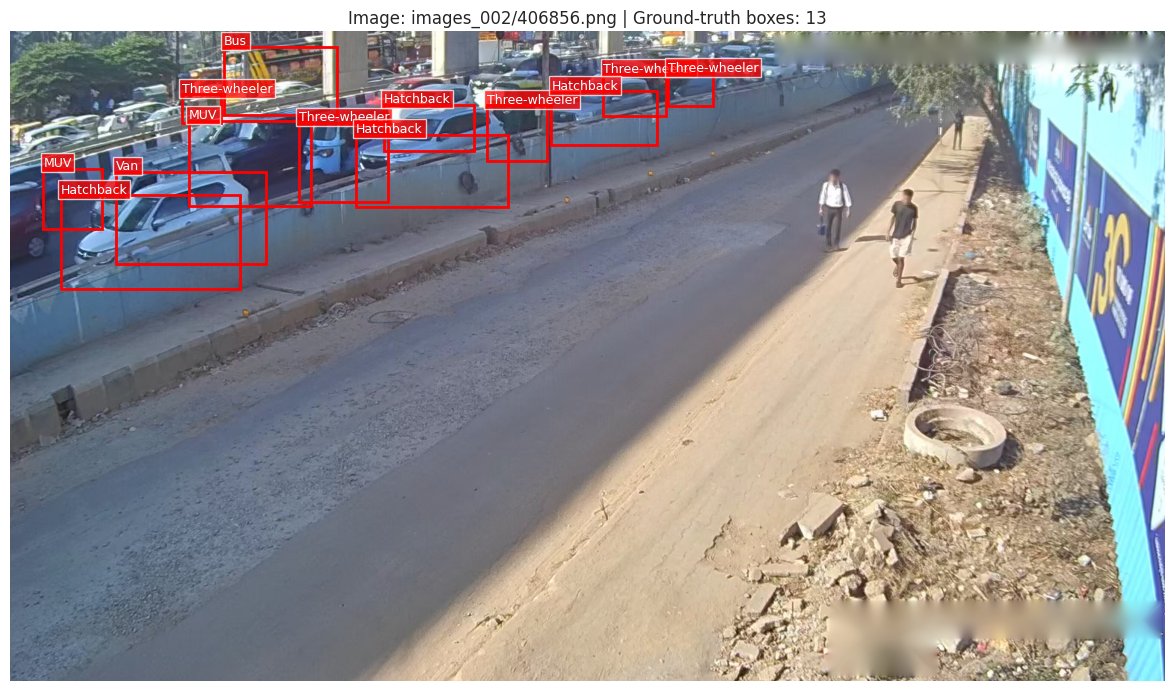

In [14]:
available_image_rows = image_df[image_df["path"].notna()].to_dict("records")

if not available_image_rows:
    print("No image files were found. Check IMAGE_DIR and file_name paths.")
else:
    random.seed(42)
    sample_rows = random.sample(
        available_image_rows,
        k=min(4, len(available_image_rows))
    )

    for row in sample_rows:
        img_bgr = cv2.imread(row["path"])
        if img_bgr is None:
            print("Could not read:", row["path"])
            continue

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        anns = coco.loadAnns(coco.getAnnIds(imgIds=[row["image_id"]]))

        fig, ax = plt.subplots(figsize=(12, 7))
        ax.imshow(img_rgb)

        for ann in anns:
            x, y, w, h = ann["bbox"]
            label = category_id_to_name.get(ann["category_id"], str(ann["category_id"]))

            rect = Rectangle(
                (x, y), w, h,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )
            ax.add_patch(rect)
            ax.text(
                x, max(0, y - 4), label,
                color="white",
                fontsize=9,
                bbox={"facecolor": "red", "alpha": 0.75, "pad": 2}
            )

        ax.set_title(f"Image: {row['file_name']} | Ground-truth boxes: {len(anns)}")
        ax.axis("off")
        plt.tight_layout()
        plt.show()

In [15]:
num_images = len(images)
num_annotations = len(annotations)
num_categories = len(categories)
num_found = int(image_df["path"].notna().sum())
avg_objects = float(objects_df["object_count"].mean()) if len(objects_df) else 0

print("=" * 58)
print("VISIONPORT — COCO DATASET EXPLORATION REPORT")
print("=" * 58)
print(f"Images listed in annotations : {num_images:,}")
print(f"Image files found            : {num_found:,}")
print(f"Image files missing          : {num_images - num_found:,}")
print(f"Object annotations           : {num_annotations:,}")
print(f"Categories                   : {num_categories:,}")
print(f"Valid bounding boxes         : {len(bbox_df):,}")
print(f"Average objects per image    : {avg_objects:.2f}")

print("\nCategory counts:")
display(category_df)

if len(category_df):
    print("Most frequent category:", category_df.iloc[0]["category"])
    nonzero = category_df[category_df["object_count"] > 0]
    if len(nonzero):
        print("Least frequent category with annotations:",
              nonzero.iloc[-1]["category"])

print("\nAudit checks:")
print("All image files found:", num_found == num_images)
print("At least one annotation:", num_annotations > 0)
print("At least one category:", num_categories > 0)
print("=" * 58)

VISIONPORT — COCO DATASET EXPLORATION REPORT
Images listed in annotations : 35,792
Image files found            : 12
Image files missing          : 35,780
Object annotations           : 373,132
Categories                   : 13
Valid bounding boxes         : 373,132
Average objects per image    : 10.43

Category counts:


,category_id,category,object_count
7,7,Two-wheeler,171283
6,6,Three-wheeler,65899
0,0,Hatchback,35101
1,1,Sedan,19970
8,8,LCV,18115
2,2,SUV,15573
4,4,Bus,13899
5,5,Truck,9968
3,3,MUV,9092
11,11,Bicycle,4713


Most frequent category: Two-wheeler
Least frequent category with annotations: Mini-bus

Audit checks:
All image files found: False
At least one annotation: True
At least one category: True


In [16]:
OUTPUT_DIR = "/content/visionport_dataset_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

category_df.to_csv(os.path.join(OUTPUT_DIR, "category_distribution.csv"), index=False)
bbox_df.to_csv(os.path.join(OUTPUT_DIR, "bounding_box_analysis.csv"), index=False)
objects_df.to_csv(os.path.join(OUTPUT_DIR, "objects_per_image.csv"), index=False)
image_df.drop(columns=["path"]).to_csv(os.path.join(OUTPUT_DIR, "image_metadata.csv"), index=False)

print("Analysis CSV files saved in:", OUTPUT_DIR)
print("Files:", os.listdir(OUTPUT_DIR))

# Optional: download all CSV reports as one ZIP
report_zip = "/content/visionport_dataset_analysis.zip"
with zipfile.ZipFile(report_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in os.listdir(OUTPUT_DIR):
        zf.write(os.path.join(OUTPUT_DIR, filename), arcname=filename)

print("ZIP report created:", report_zip)

# Uncomment to download:
# from google.colab import files
# files.download(report_zip)

Analysis CSV files saved in: /content/visionport_dataset_analysis
Files: ['objects_per_image.csv', 'category_distribution.csv', 'image_metadata.csv', 'bounding_box_analysis.csv']
ZIP report created: /content/visionport_dataset_analysis.zip
